In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- edit these two to match your CSV ---
DATE_COL  = "date"
LEVEL_COL = "water_level_mean"
# ----------------------------------------

DATA_PATH  = "../data/processed/kaub_water_weather_daily.csv"
HORIZON    = 7       # forecast 7 days ahead
TEST_YEARS = 3       # hold out the most recent 3 years

pd.set_option("display.width", 120)


date                 datetime64[us]
water_level_mean            float64
water_level_min             float64
water_level_max             float64
temperature_mean            float64
humidity_mean               float64
precipitation_sum           float64
rain_sum                    float64
snowfall_sum                float64
pressure_mean               float64
wind_speed_mean             float64
dtype: object
        date  water_level_mean  water_level_min  water_level_max  temperature_mean  humidity_mean  precipitation_sum  \
0 2000-01-01        438.989130           420.75           458.25          3.286957      97.434783                1.7   
1 2000-01-02        401.260417           385.25           419.00          3.979167      96.291667                0.0   
2 2000-01-03        367.989583           359.25           383.50          2.350000      94.458333                0.0   

   rain_sum  snowfall_sum  pressure_mean  wind_speed_mean  
0       1.7           0.0    1025.256522         

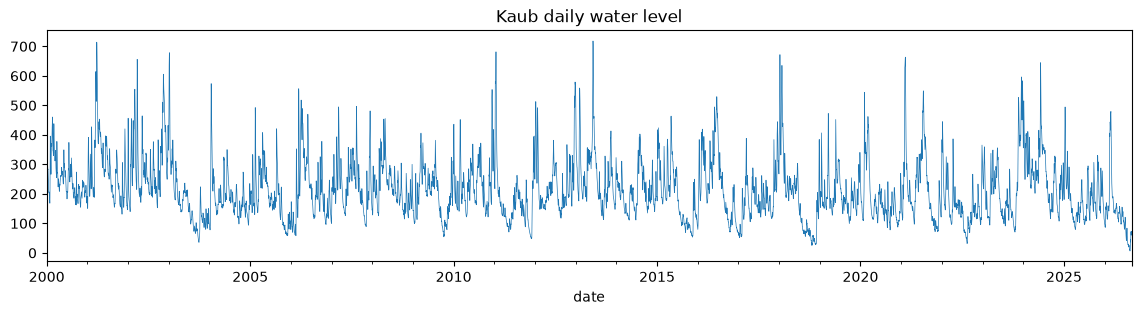

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(df.dtypes)
print(df.head(3))# sanity-check your two constants

s = (df[[DATE_COL, LEVEL_COL]]
     .dropna(subset=[DATE_COL])
     .sort_values(DATE_COL)
     .drop_duplicates(subset=[DATE_COL], keep="last")
     .set_index(DATE_COL)[LEVEL_COL]
     .asfreq("D"))                            # explicit NaN for absent days

print(f"{s.index.min().date()} → {s.index.max().date()}  ({len(s)} days)")
print("missing days:", int(s.isna().sum()))
s.plot(figsize=(14, 3), lw=0.5, title="Kaub daily water level")
plt.show()


In [3]:
H    = HORIZON
LAGS = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28]

data = pd.DataFrame(index=s.index)
for L in LAGS:
    data[f"lag_{L}"] = s.shift(L)            # all ≤ day t
data["target"] = s.shift(-H)                 # day t+7

FEATURES = [f"lag_{L}" for L in LAGS]
data.head(35)


,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_14,lag_21,lag_28,target
date,,,,,,,,,,,,
2000-01-01,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,304.572917
2000-01-02,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,293.968750
2000-01-03,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,285.385417
2000-01-04,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,282.166667
2000-01-05,327.968750,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,284.072917
2000-01-06,311.135417,327.968750,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,272.229167
2000-01-07,303.635417,311.135417,327.968750,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,259.875000
2000-01-08,304.572917,303.635417,311.135417,327.968750,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,250.281250
2000-01-09,293.968750,304.572917,303.635417,311.135417,327.968750,346.093750,367.989583,401.260417,NaN,NaN,NaN,237.739583


In [4]:
i = 400
row = data.iloc[i]
assert row["lag_0"] == s.iloc[i]                 # feature is today
assert row["target"] == s.iloc[i + H]            # target is today + 7
print(f"on {data.index[i].date()}: today={row['lag_0']}, target(+7d)={row['target']}")


on 2001-02-04: today=230.09375, target(+7d)=308.15625


In [5]:
split_date = data.index.max() - pd.DateOffset(years=TEST_YEARS)

train = data.loc[: split_date - pd.Timedelta(days=H)].dropna()
test  = data.loc[split_date + pd.Timedelta(days=1):].dropna()

X_train, y_train = train[FEATURES], train["target"]
X_test,  y_test  = test[FEATURES],  test["target"]

print(f"train: {train.index.min().date()} → {train.index.max().date()}  n={len(train)}")
print(f"test : {test.index.min().date()} → {test.index.max().date()}  n={len(test)}")
assert train.index.max() + pd.Timedelta(days=H) < test.index.min(), "embargo violated"


train: 2000-01-29 → 2023-08-25  n=8610
test : 2023-09-02 → 2026-08-25  n=1089


In [6]:
pred_persist = X_test["lag_0"].rename("persistence")


In [7]:
from sklearn.linear_model import LinearRegression

ar = LinearRegression()
ar.fit(X_train, y_train)

pred_ar = pd.Series(ar.predict(X_test), index=X_test.index, name="linear_ar")

print(pd.Series(ar.coef_, index=FEATURES).round(3))
print("intercept:", round(ar.intercept_, 2))


lag_0     1.807
lag_1    -2.006
lag_2     1.105
lag_3    -0.433
lag_4     0.130
lag_5     0.060
lag_6    -0.192
lag_7     0.203
lag_14    0.096
lag_21    0.007
lag_28    0.006
dtype: float64
intercept: 46.59


In [8]:
def evaluate(y_true, y_pred, name):
    err = y_true - y_pred
    return pd.Series({
        "MAE":  err.abs().mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "bias": err.mean(),
    }, name=name)

results = pd.concat([
    evaluate(y_test, pred_persist, "persistence"),
    evaluate(y_test, pred_ar,      "linear_ar"),
], axis=1).T

rmse_p, rmse_a = results.loc["persistence", "RMSE"], results.loc["linear_ar", "RMSE"]
results["skill_vs_persistence"] = [0.0, 1 - (rmse_a ** 2) / (rmse_p ** 2)]

print(f"Horizon: {H} days   |   test n = {len(y_test)}")
print(results.round(3))


Horizon: 7 days   |   test n = 1089
                MAE    RMSE   bias  skill_vs_persistence
persistence  50.834  72.464 -0.943                 0.000
linear_ar    49.032  66.857 -1.708                 0.149


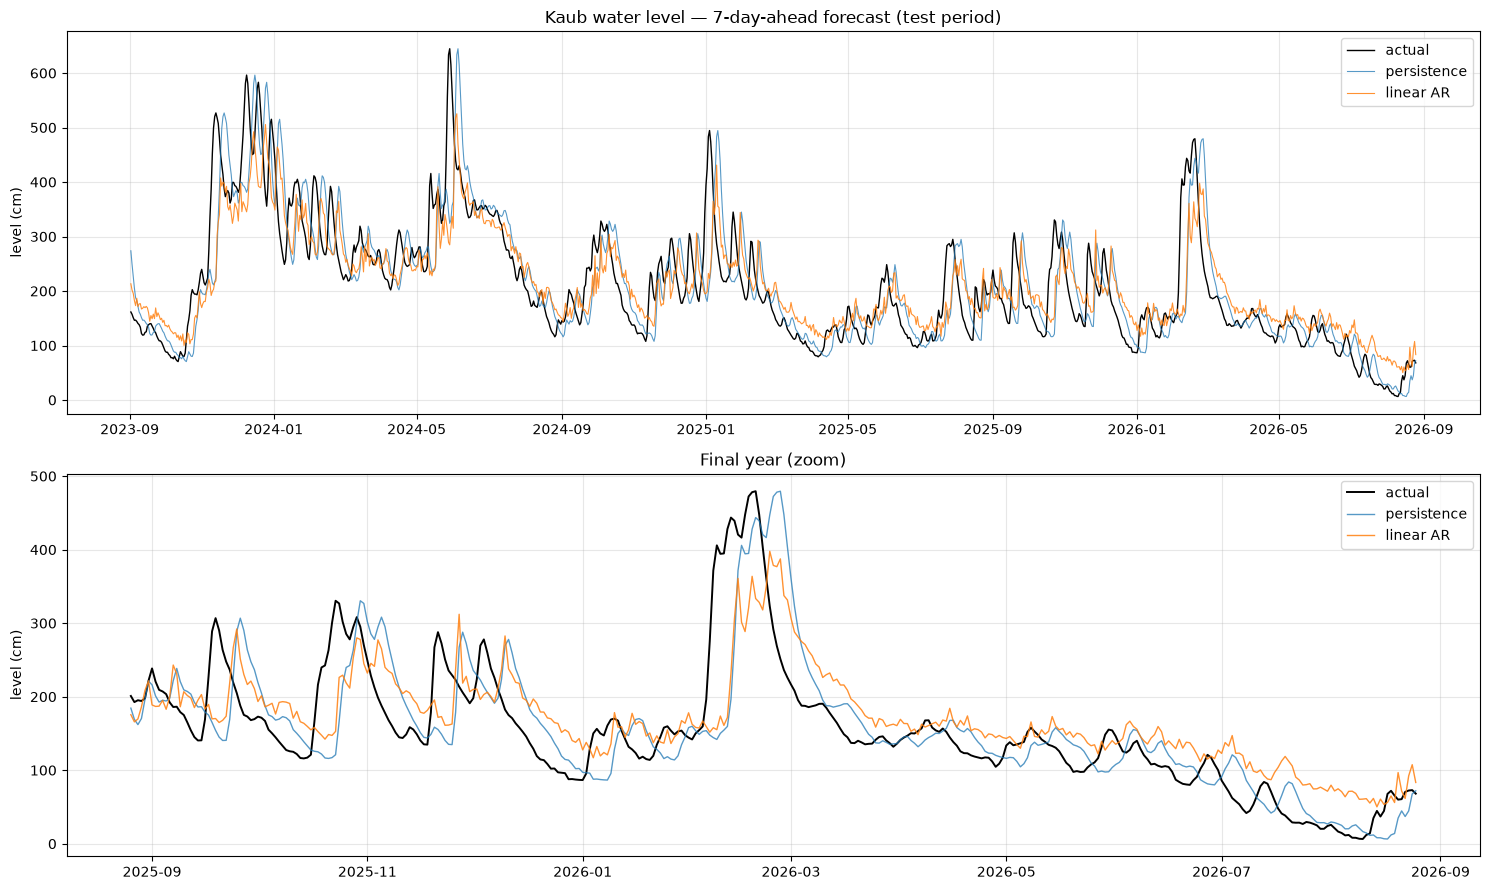

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

ax = axes[0]
ax.plot(y_test.index, y_test,      lw=1.0, color="black", label="actual")
ax.plot(pred_persist.index, pred_persist, lw=0.8, alpha=.75, label="persistence")
ax.plot(pred_ar.index, pred_ar,          lw=0.8, alpha=.85, label="linear AR")
ax.set_title(f"Kaub water level — {H}-day-ahead forecast (test period)")
ax.set_ylabel("level (cm)"); ax.legend(); ax.grid(alpha=.3)

zoom = y_test.index[-365:]
ax = axes[1]
ax.plot(zoom, y_test.loc[zoom],      lw=1.4, color="black", label="actual")
ax.plot(zoom, pred_persist.loc[zoom], lw=1.0, alpha=.75, label="persistence")
ax.plot(zoom, pred_ar.loc[zoom],      lw=1.0, alpha=.85, label="linear AR")
ax.set_title("Final year (zoom)"); ax.set_ylabel("level (cm)")
ax.legend(); ax.grid(alpha=.3)

plt.tight_layout(); plt.show()


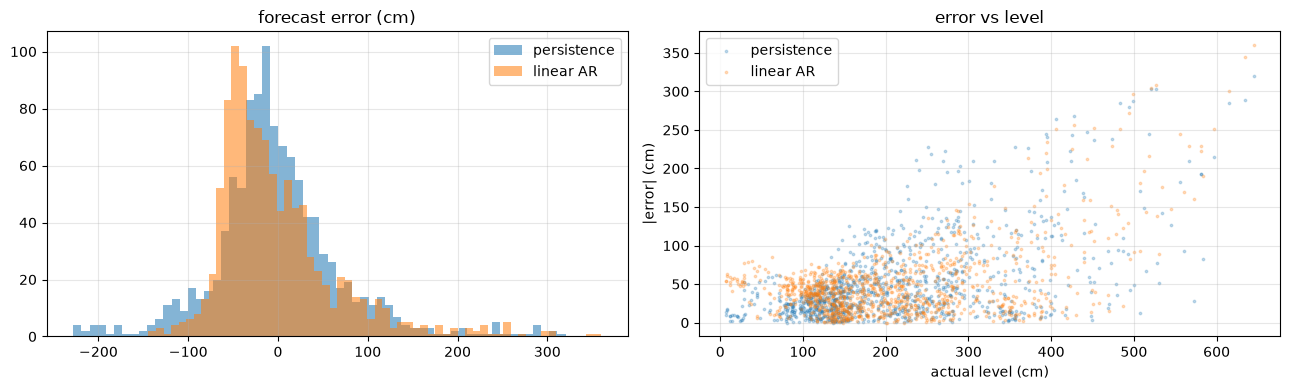

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for p, n in [(pred_persist, "persistence"), (pred_ar, "linear AR")]:
    ax[0].hist(y_test - p, bins=60, alpha=.55, label=n)
    ax[1].scatter(y_test, (y_test - p).abs(), s=3, alpha=.25, label=n)
ax[0].set_title("forecast error (cm)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set_xlabel("actual level (cm)"); ax[1].set_ylabel("|error| (cm)")
ax[1].set_title("error vs level"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


### Tracking with MLFLOW

In [ ]:
EXPERIMENT_NAME = "hydroload-baseline"

# --- Data ---
DATE_COL  = "date"
LEVEL_COL = "water_level_mean"
DATA_PATH = "data/processed/kaub_water_weather_daily.csv"

# --- Prognose-Setup ---
HORIZON    = 7
TEST_YEARS = 3
LAGS       = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28]


REGIME = {"lowwater_100": 100, "glw_78": 78, "critical_40": 40}

In [13]:
import sys
sys.path.append("..")

import warnings
import numpy as np
import pandas as pd
import mlflow
from sklearn.linear_model import LinearRegression, Ridge

from modeling.config import (TRACKING_URI, EXPERIMENT_NAME, DATE_COL, LEVEL_COL,
                             DATA_PATH, HORIZON, TEST_YEARS, LAGS, REGIME)

warnings.filterwarnings("ignore")

print("Tracking-URI :", TRACKING_URI)
print("Experiment   :", EXPERIMENT_NAME)
print("Datendatei   :", DATA_PATH.exists())

Tracking-URI : sqlite:////Users/nabilelfadel/neuefische_course/Rhine-cargo-advisor/mlflow.db
Experiment   : hydroload-baseline
Datendatei   : True


In [14]:
df = pd.read_csv(DATA_PATH, parse_dates=[DATE_COL])

s = (df[[DATE_COL, LEVEL_COL]]
       .dropna(subset=[DATE_COL])
       .sort_values(DATE_COL)
       .drop_duplicates(subset=[DATE_COL], keep="last")
       .set_index(DATE_COL)[LEVEL_COL]
       .asfreq("D"))

print(f"{s.index.min().date()} -> {s.index.max().date()}  ({len(s)} Tage)")
print("fehlende Tage:", int(s.isna().sum()))

2000-01-01 -> 2026-09-01  (9741 Tage)
fehlende Tage: 0


In [15]:
def make_data(log_target: bool = False):
    z = np.log(s) if log_target else s

    d = pd.DataFrame(index=s.index)
    for L in LAGS:
        d[f"lag_{L}"] = z.shift(L)
    d["target"] = z.shift(-HORIZON)

    split = d.index.max() - pd.DateOffset(years=TEST_YEARS)
    train = d.loc[: split - pd.Timedelta(days=HORIZON)].dropna()
    test  = d.loc[split + pd.Timedelta(days=1):].dropna()
    assert train.index.max() + pd.Timedelta(days=HORIZON) < test.index.min(), \
        "Embargo verletzt"

    F = [f"lag_{L}" for L in LAGS]
    return train[F], train["target"], test[F], test["target"], test.index


X_train, y_train, X_test, y_test, test_idx = make_data()
print(f"train: {X_train.index.min().date()} -> {X_train.index.max().date()}  n={len(X_train)}")
print(f"test : {X_test.index.min().date()} -> {X_test.index.max().date()}  n={len(X_test)}")

train: 2000-01-29 -> 2023-08-25  n=8610
test : 2023-09-02 -> 2026-08-25  n=1089


In [16]:
def evaluate(actual, pred, level_today):
    err  = actual - pred
    perr = actual - level_today

    met = {
        "MAE":  float(np.abs(err).mean()),
        "RMSE": float(np.sqrt((err ** 2).mean())),
        "bias": float(err.mean()),
        "baseline-MAE": float(np.abs(perr).mean()),
    }
    met["skill-vs-persistence-pct"] = 100 * (1 - met["MAE"] / met["baseline-MAE"])

    for label, thr in REGIME.items():
        m = actual < thr
        if m.sum():
            met[f"MAE-{label}"]  = float(np.abs(err)[m].mean())
            met[f"bias-{label}"] = float(err[m].mean())
            met[f"n-{label}"]    = int(m.sum())
            met[f"skill-{label}-pct"] = float(
                100 * (1 - met[f"MAE-{label}"] / np.abs(perr)[m].mean()))
    return met


mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)


def run_baseline(name, model=None, log_target=False, **extra_params):
    Xtr, ytr, Xte, yte, idx = make_data(log_target)

    level_today = s.reindex(idx).values
    actual = s.reindex(idx + pd.Timedelta(days=HORIZON)).values

    mlflow.start_run(run_name=name)
    run = mlflow.active_run()
    print(f"Active run_id: {run.info.run_id}  ({name})")

    if model is None:
        y_train_pred = s.reindex(Xtr.index).values
        pred = level_today
    else:
        model.fit(Xtr, ytr)
        raw_tr, raw_te = model.predict(Xtr), model.predict(Xte)
        y_train_pred = np.exp(raw_tr) if log_target else raw_tr
        pred         = np.exp(raw_te) if log_target else raw_te

    actual_train = s.reindex(Xtr.index + pd.Timedelta(days=HORIZON)).values
    mae_train = float(np.abs(actual_train - y_train_pred).mean())
    met_test  = evaluate(actual, pred, level_today)

    mlflow.log_params({
        "model": name, "log_target": log_target, "horizon": HORIZON,
        "n_lags": len(LAGS), "max_lag": max(LAGS), "test_years": TEST_YEARS,
        "train_end": str(Xtr.index.max().date()),
        "test_start": str(Xte.index.min().date()),
        "n_train": len(Xtr), "n_test": len(Xte),
        **extra_params,
    })

    mlflow.set_tag("running_from_jupyter", "True")
    mlflow.set_tag("stage", "baseline" if model is None else "model")
    mlflow.set_tag("family", "naive" if model is None else type(model).__name__)

    mlflow.log_metric("train-MAE", mae_train)
    for k, v in met_test.items():
        mlflow.log_metric("test-" + k, v)

    if model is not None and hasattr(model, "coef_"):
        mlflow.log_metric("coef-sum", float(np.sum(model.coef_)))
        mlflow.log_metric("intercept", float(model.intercept_))

    mlflow.end_run()

    print(f"  test-MAE {met_test['MAE']:6.2f} | "
          f"MAE<78cm {met_test.get('MAE-glw_78', np.nan):6.2f} | "
          f"Skill {met_test['skill-vs-persistence-pct']:+5.1f} % | "
          f"Skill<78cm {met_test.get('skill-glw_78-pct', np.nan):+6.1f} %\n")
    return met_test

2026/09/18 16:10:29 INFO mlflow.tracking.fluent: Experiment with name 'hydroload-baseline' does not exist. Creating a new experiment.


In [17]:
ergebnisse = {
    "persistence":   run_baseline("persistence"),
    "linear_ar":     run_baseline("linear_ar", LinearRegression()),
    "ridge_100":     run_baseline("ridge_100", Ridge(alpha=100), alpha=100),
    "linear_ar_log": run_baseline("linear_ar_log", LinearRegression(), log_target=True),
    "ridge_100_log": run_baseline("ridge_100_log", Ridge(alpha=100),
                                  log_target=True, alpha=100),
}

pd.DataFrame(ergebnisse).T[
    ["MAE", "RMSE", "skill-vs-persistence-pct",
     "MAE-glw_78", "skill-glw_78-pct", "MAE-critical_40"]
].round(2)

Active run_id: 3ffd8b8d9d9745e1bc41f9342bee7bca  (persistence)
  test-MAE  50.83 | MAE<78cm  23.47 | Skill  +0.0 % | Skill<78cm   +0.0 %

Active run_id: 5b18d2cb9fbb4a8ca7ea10a67710c255  (linear_ar)
  test-MAE  49.03 | MAE<78cm  46.70 | Skill  +3.5 % | Skill<78cm  -99.0 %

Active run_id: 153808802f6a4acab1116c4739290841  (ridge_100)
  test-MAE  49.03 | MAE<78cm  46.70 | Skill  +3.5 % | Skill<78cm  -99.0 %

Active run_id: 30d486d819a84f55b010e62510643c77  (linear_ar_log)
  test-MAE  46.98 | MAE<78cm  31.20 | Skill  +7.6 % | Skill<78cm  -32.9 %

Active run_id: b12fe5d3a2da42ff91668fc9158297a4  (ridge_100_log)
  test-MAE  49.42 | MAE<78cm  33.59 | Skill  +2.8 % | Skill<78cm  -43.1 %



,MAE,RMSE,skill-vs-persistence-pct,MAE-glw_78,skill-glw_78-pct,MAE-critical_40
persistence,50.83,72.46,0.00,23.47,0.00,16.76
linear_ar,49.03,66.86,3.55,46.70,-98.96,54.49
ridge_100,49.03,66.86,3.54,46.70,-98.97,54.50
linear_ar_log,46.98,66.72,7.58,31.20,-32.93,26.63
ridge_100_log,49.42,69.24,2.79,33.59,-43.11,31.17
